базовые импорты

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

импорты для дата анализа

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

импорты метрик

In [ ]:
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix

модель

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# data analиз

In [ ]:
!gdown 1KWlcYkMkDIZdATT2TTcnIfudNP-PSUci

Downloading...
From: https://drive.google.com/uc?id=1KWlcYkMkDIZdATT2TTcnIfudNP-PSUci
To: /content/titanic.csv
100% 61.2k/61.2k [00:00<00:00, 21.1MB/s]


In [ ]:
data = pd.read_csv('titanic.csv', index_col='PassengerId')

In [ ]:
data['Title'] = data.Name.str.extract(' ([A-Za-z]+)\.', expand=False)

pd.crosstab(data['Title'], data['Sex'])

<>:1: SyntaxWarning: invalid escape sequence '\.'
<>:1: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_520/3680378333.py:1: SyntaxWarning: invalid escape sequence '\.'
  data['Title'] = data.Name.str.extract(' ([A-Za-z]+)\.', expand=False)


Sex,female,male
Title,,
Capt,0,1
Col,0,2
Countess,1,0
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40


In [ ]:
data['Title'] = data['Title'].replace(['Lady', 'Countess','Capt', 'Col',\
 	'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')

data['Title'] = data['Title'].replace('Mlle', 'Miss')
data['Title'] = data['Title'].replace('Ms', 'Miss')
data['Title'] = data['Title'].replace('Mme', 'Mrs')

In [ ]:
data['Fare'] = np.log1p(data['Fare'])

In [ ]:
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
data['IsAlone']    = (data['FamilySize'] == 1).astype(int)

In [ ]:
data.drop(columns=["Cabin", 'Name', 'Ticket'], inplace=True)

In [ ]:
categorical_columns = ['Pclass', 'Sex', 'SibSp', 'Parch','Embarked', 'Title']

categorical_features = data[categorical_columns]

categorical_features.columns

unprocessed_cat_features = categorical_features.select_dtypes(include=[object]).columns.tolist()
data[unprocessed_cat_features]

,Sex,Embarked,Title
PassengerId,,,
1,male,S,Mr
2,female,C,Mrs
3,female,S,Miss
4,female,S,Mrs
5,male,S,Mr
...,...,...,...
887,male,S,Rare
888,female,S,Miss
889,female,S,Miss


In [ ]:
ohe = OneHotEncoder(sparse_output=False)

encoded = ohe.fit_transform(data[unprocessed_cat_features])
newdata = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(unprocessed_cat_features), index=data.index)

ohdata = pd.concat([data, newdata], axis=1)

ohdata.drop(unprocessed_cat_features, axis=1, inplace=True)

ohdata

,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Embarked_nan,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
PassengerId,,,,,,,,,,,,,,,,,,,
1,0,3,22.0,1,0,2.110213,2,0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,1,1,38.0,1,0,4.280593,2,0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1,3,26.0,0,0,2.188856,1,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,1,1,35.0,1,0,3.990834,2,0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
5,0,3,35.0,0,0,2.202765,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887,0,2,27.0,0,0,2.639057,1,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
888,1,1,19.0,0,0,3.433987,1,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
889,0,3,NaN,1,2,3.196630,4,0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
x = ohdata.drop(columns=['Survived'])
y = ohdata['Survived']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
numimp = KNNImputer(missing_values=np.nan, n_neighbors=5)

x_train = numimp.fit_transform(x_train)
x_test = numimp.transform(x_test)

In [ ]:
x_train

array([[ 3. , 31.4,  0. , ...,  1. ,  0. ,  0. ],
       [ 2. , 36.6,  0. , ...,  1. ,  0. ,  0. ],
       [ 1. , 34.2,  0. , ...,  1. ,  0. ,  0. ],
       ...,
       [ 3. , 48. ,  1. , ...,  0. ,  1. ,  0. ],
       [ 1. , 47. ,  0. , ...,  1. ,  0. ,  0. ],
       [ 1. , 49. ,  0. , ...,  1. ,  0. ,  0. ]], shape=(712, 18))

# baseline gradient boosting

In [ ]:
model_gboost = GradientBoostingClassifier()

model_gboost.fit(x_train, y_train)

pred_gb = model_gboost.predict(x_test)

In [ ]:
acc_gb = accuracy_score(y_test, pred_gb)
prec_gb = precision_score(y_test, pred_gb)
rec_gb = recall_score(y_test, pred_gb)
f1_gb = f1_score(y_test, pred_gb)

pd.Series([acc_gb, prec_gb, rec_gb, f1_gb])

,0
0,0.826816
1,0.816667
2,0.710145
3,0.759690


# Гиперпараметры

Для градиентного бустинга для подбора выберем

n_estimators - количество деревьев

max_depth - максимальная глубина дерева

learning_rate - коэффициент обучения


In [ ]:
grid = {
    'n_estimators' : [100, 200, 300, 400],
    'max_depth' : [2, 3, 4, 5],
    'learning_rate' : [0.01, 0.02, 0.05, 0.1],
}

grid_large = {
    'n_estimators' : [50, 100, 200, 300, 400, 500],
    'max_depth' : [2, 3, 4, 5, 6],
    'learning_rate' : [0.01, 0.02, 0.05, 0.08, 0.1],
}

# GridSearch

In [ ]:
gridsearch = GridSearchCV(GradientBoostingClassifier(), grid, cv=4, scoring='f1', n_jobs=-1)

gridsearch.fit(x_train, y_train)

GridSearchCV(cv=4, estimator=GradientBoostingClassifier(), n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.02, 0.05, 0.1],
                         'max_depth': [2, 3, 4, 5],
                         'n_estimators': [100, 200, 300, 400]},
             scoring='f1')

In [ ]:
gridsearch.best_params_

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}

In [ ]:
gridsearch.best_score_

np.float64(0.766219272446673)

In [ ]:
gridest = gridsearch.best_estimator_

f1_grid = f1_score(gridest.predict(x_test), y_test)
f1_grid

0.7596899224806202

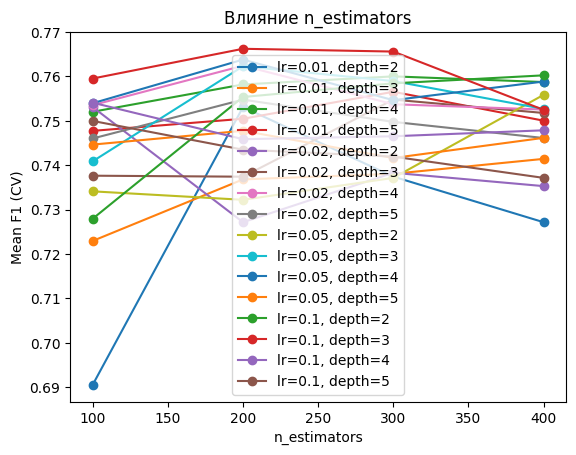

In [ ]:
results = pd.DataFrame(gridsearch.cv_results_)

# Влияние n_estimators при фиксированных max_depth и learning_rate
for lr in grid['learning_rate']:
    for depth in grid['max_depth']:
        subset = results[(results.param_learning_rate == lr) & (results.param_max_depth == depth)]
        if not subset.empty:
            plt.plot(subset.param_n_estimators, subset.mean_test_score, marker='o', label=f'lr={lr}, depth={depth}')
plt.xlabel('n_estimators')
plt.ylabel('Mean F1 (CV)')
plt.legend()
plt.title('Влияние n_estimators')
plt.show()

# RandomSearch

In [ ]:
randomsearch = RandomizedSearchCV(GradientBoostingClassifier(), param_distributions=grid_large, n_iter=30, scoring='f1',
                                  n_jobs=-1, cv=4, random_state=42)

randomsearch.fit(x_train, y_train)

RandomizedSearchCV(cv=4, estimator=GradientBoostingClassifier(), n_iter=30,
                   n_jobs=-1,
                   param_distributions={'learning_rate': [0.01, 0.02, 0.05,
                                                          0.08, 0.1],
                                        'max_depth': [2, 3, 4, 5, 6],
                                        'n_estimators': [50, 100, 200, 300, 400,
                                                         500]},
                   random_state=42, scoring='f1')

In [ ]:
randomsearch.best_params_

{'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1}

In [ ]:
randomsearch.best_score_

np.float64(0.766219272446673)

In [ ]:
randomest = randomsearch.best_estimator_

f1_random = f1_score(randomest.predict(x_test), y_test)
f1_random

0.7596899224806202

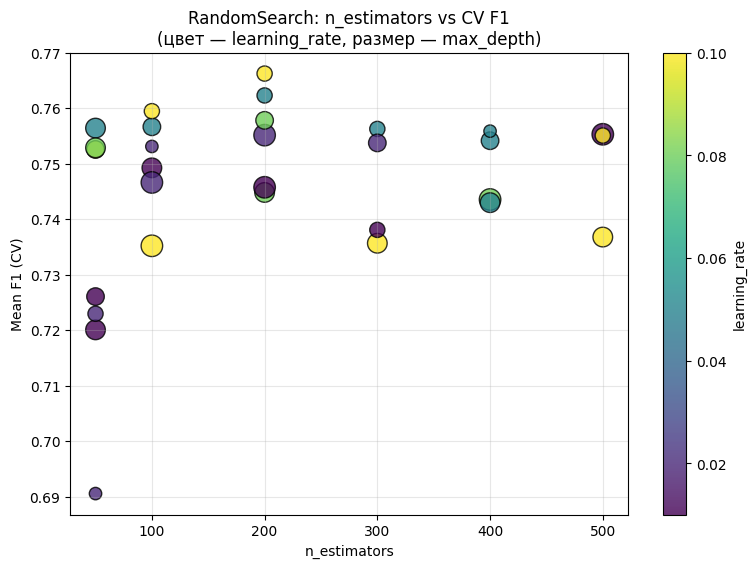

In [ ]:
rs_results = pd.DataFrame(randomsearch.cv_results_)

plt.figure(figsize=(9, 6))
sc = plt.scatter(
    rs_results['param_n_estimators'],
    rs_results['mean_test_score'],
    c=rs_results['param_learning_rate'],
    s=rs_results['param_max_depth'] * 40,
    cmap='viridis', alpha=0.8, edgecolor='k'
)
plt.colorbar(sc, label='learning_rate')
plt.xlabel('n_estimators')
plt.ylabel('Mean F1 (CV)')
plt.title('RandomSearch: n_estimators vs CV F1\n(цвет — learning_rate, размер — max_depth)')
plt.grid(alpha=0.3)
plt.show()

# comparison

In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    'Model': ['Baseline', 'GridSearch', 'RandomSearch'],
    'CV Score': [None, gridsearch.best_score_, randomsearch.best_score_],
    'Test F1': [f1_gb, f1_grid, f1_random]
})
comparison

,Model,CV Score,Test F1
0,Baseline,NaN,0.75969
1,GridSearch,0.766219,0.75969
2,RandomSearch,0.766219,0.75969


In [ ]:
# Для GridSearch
grid_fold_scores = [gridsearch.cv_results_[f'split{i}_test_score'][gridsearch.best_index_] for i in range(4)]
print("Grid folds:", grid_fold_scores, "std:", np.std(grid_fold_scores))

# Для RandomSearch
random_fold_scores = [randomsearch.cv_results_[f'split{i}_test_score'][randomsearch.best_index_] for i in range(4)]
print("Random folds:", random_fold_scores, "std:", np.std(random_fold_scores))

Grid folds: [np.float64(0.7368421052631579), np.float64(0.746031746031746), np.float64(0.8244274809160306), np.float64(0.7575757575757576)] std: 0.034400072881527084
Random folds: [np.float64(0.7368421052631579), np.float64(0.746031746031746), np.float64(0.8244274809160306), np.float64(0.7575757575757576)] std: 0.034400072881527084
